# **9. Perform image classification using a pre-trained Vision Transformer (ViT) model and compare its performance with a CNN model.**

In [ ]:
#1 Install the required libraries
!pip install -q transformers accelerate scikit-learn pillow

In [ ]:
#2 Load CIFAR-10 and select a manageable subset
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import torch
import time

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import AutoImageProcessor, ViTForImageClassification

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report
)

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

x_train, y_train = x_train[:2000], y_train[:2000].flatten()
x_test, y_test = x_test[:500], y_test[:500].flatten()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)
print("GPU available:", torch.cuda.is_available())

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 457s 3us/step
Training images: (2000, 32, 32, 3)
Testing images: (500, 32, 32, 3)
GPU available: False


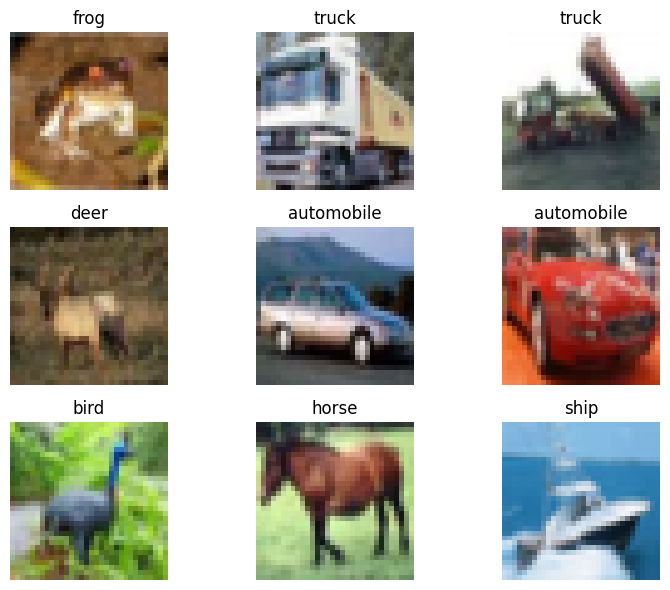

In [ ]:
#3 Display sample images
plt.figure(figsize=(8, 6))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#4 Load the pretrained ViT model
model_name = "google/vit-base-patch16-224-in21k"

processor = AutoImageProcessor.from_pretrained(model_name)

vit_model = ViTForImageClassification.from_pretrained(
    model_name,
    num_labels=10,
    ignore_mismatched_sizes=True
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vit_model.to(device)

# Freeze pretrained feature extractor; train the new 10-class head
for param in vit_model.vit.parameters():
    param.requires_grad = False

print("Pretrained ViT loaded on:", device)

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Pretrained ViT loaded on: cpu


In [ ]:
#5 Prepare the images for ViT
class CIFARDataset(Dataset):
    def __init__(self, images, labels):
        self.images = images
        self.labels = labels

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = Image.fromarray(self.images[index])
        inputs = processor(images=image, return_tensors="pt")

        return (
            inputs["pixel_values"].squeeze(0),
            torch.tensor(int(self.labels[index]), dtype=torch.long)
        )

train_loader = DataLoader(
    CIFARDataset(x_train, y_train),
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    CIFARDataset(x_test, y_test),
    batch_size=16,
    shuffle=False
)

print("ViT data loaders prepared.")

ViT data loaders prepared.


In [ ]:
#6 Train the ViT classification head
optimizer = torch.optim.AdamW(
    vit_model.classifier.parameters(),
    lr=0.001
)

epochs = 2
vit_start = time.time()

for epoch in range(epochs):
    vit_model.train()
    total_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = vit_model(pixel_values=images, labels=labels)
        loss = outputs.loss

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch + 1}/{epochs}, "
        f"Loss: {total_loss / len(train_loader):.4f}"
    )

vit_time = time.time() - vit_start
print(f"ViT training time: {vit_time:.1f} seconds")

Epoch 1/2, Loss: 1.1746
Epoch 2/2, Loss: 0.3765
ViT training time: 1932.7 seconds


In [ ]:
#7 Evaluate ViT
vit_model.eval()
vit_predictions = []
vit_actual = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = vit_model(pixel_values=images)
        predictions = outputs.logits.argmax(dim=1)

        vit_predictions.extend(predictions.cpu().numpy())
        vit_actual.extend(labels.numpy())

vit_accuracy = accuracy_score(vit_actual, vit_predictions)
vit_precision = precision_score(
    vit_actual, vit_predictions, average="macro", zero_division=0
)
vit_recall = recall_score(
    vit_actual, vit_predictions, average="macro", zero_division=0
)
vit_f1 = f1_score(
    vit_actual, vit_predictions, average="macro", zero_division=0
)

print("ViT Accuracy:", round(vit_accuracy, 4))
print("ViT Macro Precision:", round(vit_precision, 4))
print("ViT Macro Recall:", round(vit_recall, 4))
print("ViT Macro F1-score:", round(vit_f1, 4))

ViT Accuracy: 0.948
ViT Macro Precision: 0.9502
ViT Macro Recall: 0.9491
ViT Macro F1-score: 0.9491


In [ ]:
#8 Build and train a CNN
from tensorflow.keras import layers, models

def prepare_cnn_data(images, labels):
    images = tf.image.resize(images, (96, 96))
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels

cnn_train = tf.data.Dataset.from_tensor_slices((x_train, y_train))
cnn_train = cnn_train.map(prepare_cnn_data).batch(32).prefetch(tf.data.AUTOTUNE)

cnn_test = tf.data.Dataset.from_tensor_slices((x_test, y_test))
cnn_test = cnn_test.map(prepare_cnn_data).batch(32).prefetch(tf.data.AUTOTUNE)

cnn_model = models.Sequential([
    layers.Input(shape=(96, 96, 3)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_start = time.time()

cnn_model.fit(cnn_train, epochs=3, verbose=1)

cnn_time = time.time() - cnn_start

Epoch 1/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 22s 329ms/step - accuracy: 0.1305 - loss: 2.2793
Epoch 2/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 41s 329ms/step - accuracy: 0.1695 - loss: 2.1762
Epoch 3/3
63/63 ━━━━━━━━━━━━━━━━━━━━ 41s 324ms/step - accuracy: 0.1870 - loss: 2.1119


In [ ]:
#9 Evaluate CNN
cnn_probabilities = cnn_model.predict(cnn_test, verbose=0)
cnn_predictions = np.argmax(cnn_probabilities, axis=1)

cnn_actual = np.concatenate([
    labels.numpy() for _, labels in cnn_test
])

cnn_accuracy = accuracy_score(cnn_actual, cnn_predictions)
cnn_precision = precision_score(
    cnn_actual, cnn_predictions, average="macro", zero_division=0
)
cnn_recall = recall_score(
    cnn_actual, cnn_predictions, average="macro", zero_division=0
)
cnn_f1 = f1_score(
    cnn_actual, cnn_predictions, average="macro", zero_division=0
)

print("CNN Accuracy:", round(cnn_accuracy, 4))
print("CNN Macro Precision:", round(cnn_precision, 4))
print("CNN Macro Recall:", round(cnn_recall, 4))
print("CNN Macro F1-score:", round(cnn_f1, 4))

CNN Accuracy: 0.234
CNN Macro Precision: 0.1357
CNN Macro Recall: 0.2196
CNN Macro F1-score: 0.1556


In [ ]:
#10 Compare ViT and CNN
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Pretrained ViT", "CNN"],
    "Accuracy": [vit_accuracy, cnn_accuracy],
    "Macro Precision": [vit_precision, cnn_precision],
    "Macro Recall": [vit_recall, cnn_recall],
    "Macro F1-score": [vit_f1, cnn_f1],
    "Training Time (sec)": [vit_time, cnn_time]
})

print(comparison.round(4))

            Model  Accuracy  Macro Precision  Macro Recall  Macro F1-score  \
0  Pretrained ViT     0.948           0.9502        0.9491          0.9491   
1             CNN     0.234           0.1357        0.2196          0.1556   

   Training Time (sec)  
0            1932.6707  
1             103.7549  


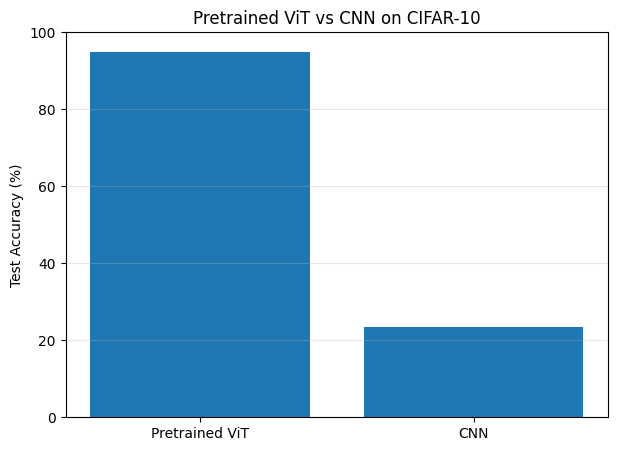

In [ ]:
#11 Plot the accuracy comparison
plt.figure(figsize=(7, 5))

plt.bar(comparison["Model"], comparison["Accuracy"] * 100)

plt.title("Pretrained ViT vs CNN on CIFAR-10")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
#12 Classification report
print("PRETRAINED ViT")
print(classification_report(
    vit_actual, vit_predictions,
    labels=list(range(10)),
    target_names=class_names,
    zero_division=0
))

print("CNN")
print(classification_report(
    cnn_actual, cnn_predictions,
    labels=list(range(10)),
    target_names=class_names,
    zero_division=0
))

PRETRAINED ViT
              precision    recall  f1-score   support

    airplane       0.91      0.93      0.92        57
  automobile       0.95      0.93      0.94        41
        bird       1.00      0.96      0.98        51
         cat       0.86      0.98      0.91        49
        deer       0.95      0.97      0.96        40
         dog       0.96      0.94      0.95        48
        frog       0.98      0.94      0.96        54
       horse       1.00      0.98      0.99        47
        ship       0.95      0.93      0.94        57
       truck       0.95      0.93      0.94        56

    accuracy                           0.95       500
   macro avg       0.95      0.95      0.95       500
weighted avg       0.95      0.95      0.95       500

CNN
              precision    recall  f1-score   support

    airplane       0.30      0.51      0.38        57
  automobile       0.00      0.00      0.00        41
        bird       0.00      0.00      0.00        51
     